# Cours 3 : Machine Learning - Algorithmes supervisés (1/3)

## Préambule

Les objectifs de cette séance (3h) sont :
* Préparation des bases de modélisation (sampling)
* Mettre en application un modèle supervisé simple.
* Construire un modèle de Machine Learning (cross-validation et hyperparamétrage) pour résoudre un problème de régression
* Analyser les performances du modèle

## Préparation du workspace

### Import de librairies 

In [5]:
# Données
import pandas as pd
import numpy as np

#Graphiques 
import seaborn as sns
sns.set()
import plotly.express as px
import plotly.graph_objects as gp

#Statistiques
from scipy.stats import chi2_contingency

# Machine Learning
from sklearn.cluster import KMeans
import sklearn.preprocessing as preproc
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn import metrics

### Définition des fonctions 

### Constantes

In [6]:
input_path = "./1_inputs"
output_path = "./2_outputs"

### Import des données

In [7]:
path =input_path + '/base_retraitee.csv'
data_retraitee = pd.read_csv(path,sep=",",decimal=".")

## Algorithme supervisé : CART 

Dans cette partie l'objectif est de construire un modèle simple (algorithme CART) afin de voir les différentes étapes nécessaire au lancement d'un modèle
Nous modéliserons directement le coût des sinistres. 

### Construction du modèle

La première étape est de calculer les côut moyen de chaque sinistre (target ou variable réponse). Cette variable sera la variable à prédire en fonction des variables explicatives.

In [8]:
data_model = data_retraitee

#Filtre pour ne garder que les lignes qui ont un sinistre (NB > 0)
data_model = data_model[data_model['NB'] > 0]

#Calcul du cout moyen "théorique" des sinistres
data_model["CM"] = (data_model["CHARGE"] / data_model["NB"])
data_model = data_model.drop(['CHARGE', 'NB', "EXPO"], axis=1)
data_model.head()

,ANNEE_CTR,CONTRAT_ANCIENNETE,FREQUENCE_PAIEMENT_COTISATION,GROUPE_KM,ZONE_RISQUE,AGE_ASSURE_PRINCIPAL,GENRE,DEUXIEME_CONDUCTEUR,ANCIENNETE_PERMIS,ANNEE_CONSTRUCTION,ENERGIE,EQUIPEMENT_SECURITE,VALEUR_DU_BIEN,CM
10,2023,"(0,1]",MENSUEL,[0;20000[,C,40,M,False,37,2021.0,ESSENCE,VRAI,[15000;20000[,1072.98
34,2024,"(-1,0]",MENSUEL,[20000;40000[,C,27,M,True,13,2022.0,AUTRE,FAUX,[35000;99999[,3750.00
36,2023,"(-1,0]",MENSUEL,[20000;40000[,L,19,M,False,2,2021.0,ESSENCE,VRAI,[0;10000[,1838.49
78,2023,"(-1,0]",MENSUEL,[20000;40000[,B,40,M,False,45,2022.0,DIESEL,FAUX,[15000;20000[,4892.74
89,2022,"(1,2]",MENSUEL,[20000;40000[,C,20,M,False,11,2018.0,ESSENCE,FAUX,[25000;35000[,166.73


**Exercice :** construisez les statistiques descriptives de la base utilisée.

In [26]:
# Statistiques descriptives de la base modélisée
display(data_model.describe(include="all").T)

print("Dimensions :", data_model.shape)
print("Valeurs manquantes par variable :")
display(data_model.isna().sum().to_frame("Valeurs manquantes"))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ANNEE_CTR,824.0,NaN,NaN,NaN,2022.384709,1.515833,2020.0,2021.0,2022.0,2024.0,2025.0
CONTRAT_ANCIENNETE,824,5,"(0,1]",297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FREQUENCE_PAIEMENT_COTISATION,824,3,MENSUEL,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GROUPE_KM,824,4,[0;20000[,391,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZONE_RISQUE,824,14,C,269,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AGE_ASSURE_PRINCIPAL,824.0,NaN,NaN,NaN,44.383495,13.808217,19.0,34.0,43.0,53.0,94.0
GENRE,824,2,M,483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DEUXIEME_CONDUCTEUR,824,2,False,663,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ANCIENNETE_PERMIS,824.0,NaN,NaN,NaN,35.688107,19.370621,1.0,18.0,35.0,53.0,70.0
ANNEE_CONSTRUCTION,824.0,NaN,NaN,NaN,2019.212379,3.163782,2002.0,2018.0,2020.0,2021.0,2025.0


Dimensions : (824, 14)
Valeurs manquantes par variable :


,Valeurs manquantes
ANNEE_CTR,0
CONTRAT_ANCIENNETE,0
FREQUENCE_PAIEMENT_COTISATION,0
GROUPE_KM,0
ZONE_RISQUE,0
AGE_ASSURE_PRINCIPAL,0
GENRE,0
DEUXIEME_CONDUCTEUR,0
ANCIENNETE_PERMIS,0
ANNEE_CONSTRUCTION,0


#### Etude des corrélations parmi les variables explicatives

**Question :** Selon vous, pourquoi faut-il s'intéresser à la corrélation des variables ?

**Réponse :** Une corrélation élevée entre variables explicatives signale qu'elles apportent potentiellement une information redondante. Cela peut rendre certains modèles sensibles à la multicolinéarité, compliquer l'interprétation et augmenter inutilement la dimension du modèle. Pour les arbres et les forêts, l'effet est moins direct que pour une régression linéaire, mais repérer les associations reste utile pour comprendre les données, limiter les redondances et éclairer le choix du modèle. Une corrélation ne prouve toutefois ni causalité ni redondance parfaite.

In [9]:
data_set = data_model.drop("CM", axis=1)

In [10]:
#Séparation en variables qualitatives ou catégorielles
variables_na = []
variables_numeriques = []
variables_01 = []
variables_categorielles = []
for colu in data_set.columns:
    if True in data_set[colu].isna().unique() :
        variables_na.append(data_set[colu])
    else :
        if str(data_set[colu].dtypes) in ["int32","int64","float64"]:
            if len(data_set[colu].unique())==2 :
                variables_categorielles.append(data_set[colu])
            else :
                variables_numeriques.append(data_set[colu])
        else :
            if len(data_set[colu].unique())==2 :
                variables_categorielles.append(data_set[colu])
            else :
                variables_categorielles.append(data_set[colu])

##### Corrélation des variables catégorielles :

In [11]:
vars_categorielles = pd.DataFrame(variables_categorielles).transpose()

,CONTRAT_ANCIENNETE,FREQUENCE_PAIEMENT_COTISATION,GROUPE_KM,ZONE_RISQUE,GENRE,DEUXIEME_CONDUCTEUR,ENERGIE,EQUIPEMENT_SECURITE,VALEUR_DU_BIEN
CONTRAT_ANCIENNETE,1.000000,0.055726,0.094358,0.144802,0.075872,0.074783,0.072223,0.055815,0.078447
FREQUENCE_PAIEMENT_COTISATION,0.055726,1.000000,0.032377,0.110824,0.105467,0.061499,0.057691,0.074046,0.176757
GROUPE_KM,0.094358,0.032377,1.000000,0.195127,0.105987,0.060626,0.210759,0.118442,0.209968
ZONE_RISQUE,0.144802,0.110824,0.195127,1.000000,0.099694,0.151856,0.185164,0.201841,0.127970
GENRE,0.075872,0.105467,0.105987,0.099694,1.000000,0.000792,0.158979,0.104717,0.277081
DEUXIEME_CONDUCTEUR,0.074783,0.061499,0.060626,0.151856,0.000792,1.000000,0.039160,0.003065,0.132452
ENERGIE,0.072223,0.057691,0.210759,0.185164,0.158979,0.039160,1.000000,0.137292,0.287577
EQUIPEMENT_SECURITE,0.055815,0.074046,0.118442,0.201841,0.104717,0.003065,0.137292,1.000000,0.219434
VALEUR_DU_BIEN,0.078447,0.176757,0.209968,0.127970,0.277081,0.132452,0.287577,0.219434,1.000000


<Axes: >

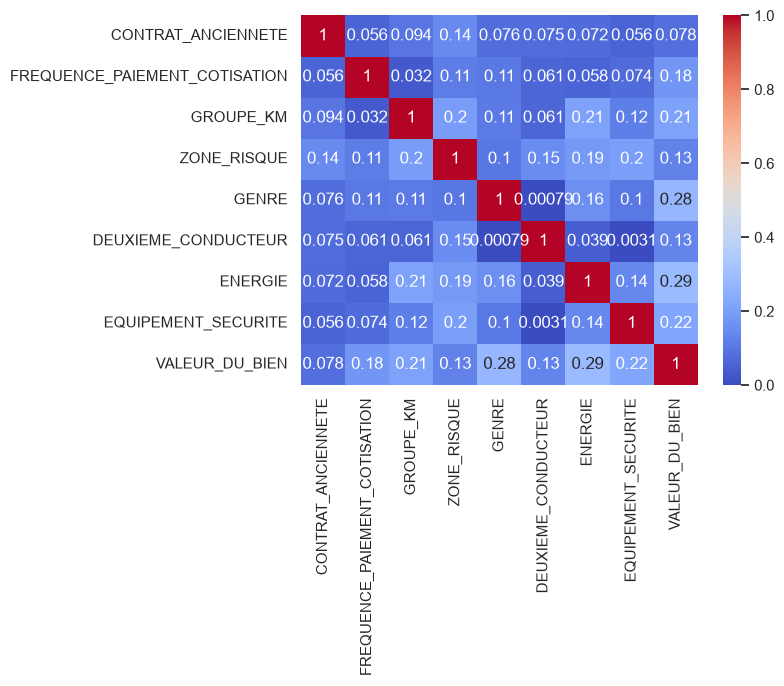

In [27]:
# V de Cramer pour mesurer l'association entre deux variables catégorielles
def cramers_v(x, y):
    contingency = pd.crosstab(x, y)
    chi2 = chi2_contingency(contingency)[0]
    n = contingency.to_numpy().sum()
    denominator = n * min(contingency.shape[0] - 1, contingency.shape[1] - 1)
    return np.sqrt(chi2 / denominator) if denominator > 0 else 0.0

categorical_correlation = pd.DataFrame(
    np.eye(len(vars_categorielles.columns)),
    index=vars_categorielles.columns,
    columns=vars_categorielles.columns,
)
for i, first_variable in enumerate(vars_categorielles.columns):
    for second_variable in vars_categorielles.columns[i + 1:]:
        association = cramers_v(vars_categorielles[first_variable], vars_categorielles[second_variable])
        categorical_correlation.loc[first_variable, second_variable] = association
        categorical_correlation.loc[second_variable, first_variable] = association

display(categorical_correlation)
sns.heatmap(categorical_correlation, annot=True, cmap="coolwarm", vmin=0, vmax=1)

##### Corrélation des variables numériques :

In [13]:
vars_numeriques = pd.DataFrame(variables_numeriques).transpose()

,ANNEE_CTR,AGE_ASSURE_PRINCIPAL,ANCIENNETE_PERMIS,ANNEE_CONSTRUCTION
ANNEE_CTR,1.000000,0.026613,0.040797,0.387562
AGE_ASSURE_PRINCIPAL,0.026613,1.000000,0.540899,-0.031655
ANCIENNETE_PERMIS,0.040797,0.540899,1.000000,0.033320
ANNEE_CONSTRUCTION,0.387562,-0.031655,0.033320,1.000000


<Axes: >

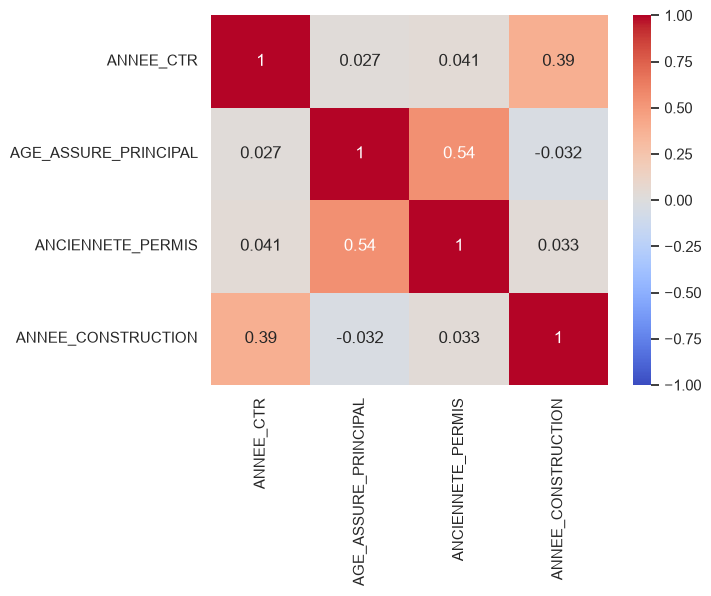

In [28]:
numeric_correlation = vars_numeriques.corr(method="pearson")
display(numeric_correlation)
sns.heatmap(numeric_correlation, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)

**Question :** quels sont vos commentaires ?

**Réponse :** Les associations entre variables catégorielles sont faibles : la plus élevée est entre `ENERGIE` et `VALEUR_DU_BIEN` (V de Cramer ≈ 0,29), suivie de `GENRE` et `VALEUR_DU_BIEN` (≈ 0,28). Pour les variables numériques, le lien le plus marqué est entre `AGE_ASSURE_PRINCIPAL` et `ANCIENNETE_PERMIS` (r ≈ 0,54), ce qui est cohérent, sans être une redondance parfaite. `ANNEE_CTR` et `ANNEE_CONSTRUCTION` présentent une corrélation modérée (r ≈ 0,39). Les autres corrélations linéaires sont faibles. Ces résultats ne justifient pas à eux seuls de supprimer une variable; ils doivent être interprétés avec le contexte métier et les performances du modèle.

#### Preprocessing

Deux étapes sont nécessaires avant de lancer l'apprentissage d'un modèle, c'est ce qu'on connait comme le *Preprocessing* :

* Les modèles proposés par la librairie "sklearn" ne gèrent que des variables numériques. Il est donc nécessaire de transformer les variables catégorielles en variables numériques : ce processus s'appelle le *One Hot Encoding*.
* Normaliser les données numériques

**Exercice :** proposez un bout de code permettant de réaliser le One Hot Encoding des variables catégorielles. Vous pourrez utiliser la fonction "preproc.OneHotEncoder" de la librairie sklearn

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_columns = vars_numeriques.columns.tolist()
categorical_columns = vars_categorielles.columns.tolist()

# Le préprocesseur sera ajusté uniquement sur les données d'entraînement.
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", preproc.StandardScaler(), numeric_columns),
        ("categorical", preproc.OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    ]
)

**Exercice :** proposez un bout de code permettant normaliser les variables numériques présentes dans la base. Vous pourrez utiliser la fonction "preproc.StandardScaler" de la librairie sklearn

In [30]:
# Le StandardScaler est ajusté plus tard par le pipeline sur X_train uniquement,
# pour éviter que les statistiques du jeu de test influencent le prétraitement.
preprocessor.set_params(numerical=preproc.StandardScaler())

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

#### Sampling

**Exercice :** proposez un bout de code permettant construire la base d'apprentissage (80% des données) et la base de test (20%).

In [31]:
X = data_model.drop(columns="CM")
y = data_model["CM"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Taille apprentissage :", X_train.shape)
print("Taille test :", X_test.shape)

Taille apprentissage : (659, 13)
Taille test : (165, 13)


#### Fitting

**Exercice :** proposez un bout de code permettant construire le modèle

In [ ]:
model_CART = DecisionTreeRegressor()
model_CART = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("regressor", DecisionTreeRegressor(random_state=42)),
    ]
)
model_CART.fit(X_train, y_train)

ValueError: could not convert string to float: '(2,5]'

**Exercice :** proposez un bout de code permettant d'évaluer les performances du modèle (MAE, MSE et RMSE)

In [ ]:
cart_predictions = model_CART.predict(X_test)

cart_mae = metrics.mean_absolute_error(y_test, cart_predictions)
cart_mse = metrics.mean_squared_error(y_test, cart_predictions)
cart_rmse = np.sqrt(cart_mse)

baseline_predictions = np.full(len(y_test), y_train.mean())
baseline_mae = metrics.mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = metrics.root_mean_squared_error(y_test, baseline_predictions)

print(f"CART MAE : {cart_mae:.2f}")
print(f"CART MSE : {cart_mse:.2f}")
print(f"CART RMSE : {cart_rmse:.2f}")
print(f"Baseline MAE (moyenne du train) : {baseline_mae:.2f}")
print(f"Baseline RMSE (moyenne du train) : {baseline_rmse:.2f}")

CART MAE : 4893.79
CART MSE : 78617899.25
CART RMSE : 8866.67
Baseline MAE (moyenne du train) : 3431.54
Baseline RMSE (moyenne du train) : 6789.72


**Question :** que pensez-vous des performances de ce modèle ?

**Réponse :** Les performances du CART sont insuffisantes sur ce jeu de test : le MAE est d'environ 4 894 et le RMSE d'environ 8 867. À titre de comparaison, prédire systématiquement la moyenne du jeu d'apprentissage donne un MAE d'environ 3 432 et un RMSE d'environ 6 790. Le CART fait donc moins bien que cette référence sur ce découpage. La cible est très asymétrique et comporte des valeurs extrêmes, ce qui pénalise particulièrement le RMSE; il faudra comparer des modèles plus robustes et évaluer leur stabilité en validation croisée.

## Algorithme supervisé : Random Forest  

A ce stade, nous avons vu les différentes étapes pour lancer un algorithme de Machine Learning. Néanmoins, ces étapes ne sont pas suffisantes pour construire un modèle performant.  
En effet, afin de construire un modèle performant le Data Scientist doit agir sur l'apprentissage du modèle. Dans ce qui suit nous :
* Changerons d'algorithme pour utiliser un algorithme plus performant (Random Forest)
* Raliserons un *grid search* sur les paramètres du modèle
* Appliquerons l'apprentissage par validation croisée


### Modèle avec Validation Croisée

#### Sampling

In [36]:
X_rf = data_model.drop(columns="CM")
y_rf = data_model["CM"]
print("Observations pour la validation croisée :", X_rf.shape[0])

Observations pour la validation croisée : 824


#### Fitting avec Cross-Validation

**Exercice :** construisez un modèle RF (RandomForestRegressor) en implémentant la technique de validation croisée. Pensez à enregistrer au sein d'une variable/liste les performances (MAE, MSE & RMSE) du modèle au sein de chaque fold.

In [51]:
# Initialisation de la validation croisée
num_splits = 5
rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
kf = KFold(n_splits=num_splits, shuffle=True, random_state=42)

MAE_scores = []
MSE_scores = []
RMSE_scores = []

In [52]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

rf_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("regressor", rf_regressor),
    ]
)
scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "rmse": "neg_root_mean_squared_error",
}
cv_results = cross_validate(
    rf_pipeline, X_rf, y_rf, cv=kf, scoring=scoring, return_train_score=False
)
MAE_scores = -cv_results["test_mae"]
MSE_scores = -cv_results["test_mse"]
RMSE_scores = -cv_results["test_rmse"]

baseline_cv_results = cross_validate(
    DummyRegressor(strategy="mean"),
    X_rf,
    y_rf,
    cv=kf,
    scoring=scoring,
    return_train_score=False,
)
print("MAE moyen de la référence :", -baseline_cv_results["test_mae"].mean())
print("RMSE moyen de la référence :", -baseline_cv_results["test_rmse"].mean())

MAE moyen de la référence : 3545.079487013375
RMSE moyen de la référence : 6744.013056308007


In [53]:
# Métriques sur tous les folds

#MAE
for fold, mae in enumerate(MAE_scores, start=1):
    print(f"Fold {fold} MAE:", mae)

Fold 1 MAE: 3709.5591169696972
Fold 2 MAE: 4593.935574545454
Fold 3 MAE: 3901.2656403030296
Fold 4 MAE: 3744.6095384848486
Fold 5 MAE: 4744.021178963414


In [54]:
#MSE
for fold, mse in enumerate(MSE_scores, start=1):
    print(f"Fold {fold} MSE:", mse)

Fold 1 MSE: 50928576.84663504
Fold 2 MSE: 80481135.9007165
Fold 3 MSE: 29898331.179755643
Fold 4 MSE: 51572258.92414797
Fold 5 MSE: 61654614.2543689


In [55]:
#RMSE
for fold, rmse in enumerate(RMSE_scores, start=1):
    print(f"Fold {fold} RMSE:", rmse)

Fold 1 RMSE: 7136.426055571167
Fold 2 RMSE: 8971.127905716008
Fold 3 RMSE: 5467.936647379489
Fold 4 RMSE: 7181.3828002793425
Fold 5 RMSE: 7852.045227478565


**Question :** Commentez les résultats.

**Réponse :** La Random Forest standard obtient en moyenne un MAE d'environ 4 139 et un RMSE d'environ 7 322, avec des RMSE allant de 5 468 à 8 971 selon le fold. Sur ces mêmes folds, la baseline qui prédit la moyenne atteint un MAE d'environ 3 545 et un RMSE d'environ 6 744. La forêt standard ne fait donc pas mieux que cette référence; les écarts entre folds montrent aussi une sensibilité à la composition des échantillons et aux coûts extrêmes. La validation croisée permet de voir cette variabilité, contrairement à un unique découpage train/test.

### Ajout d'un Grid Search pour les hyper paramètres

#### Sampling

In [45]:
X_grid = data_model.drop(columns="CM")
y_grid = data_model["CM"]
kf_grid = KFold(n_splits=5, shuffle=True, random_state=42)
print("Observations pour la recherche sur grille :", X_grid.shape[0])

Observations pour la recherche sur grille : 824


#### Fitting avec Cross-Validation et *Grid Search*

**Exercice :** Intégrez la technique de Grid Search pour rechercher les paramètres optimaux du modèle.

In [43]:
from sklearn.model_selection import GridSearchCV

num_splits = 5
kf_grid = KFold(n_splits=num_splits, shuffle=True, random_state=42)
scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "rmse": "neg_root_mean_squared_error",
}

# Grille compacte pour comparer complexité et nombre d'arbres
n_estimators_values = [50, 100]
max_depth_values = [None, 8]
min_samples_split_values = [2, 10]

best_score = np.inf
best_params = {}
MAE_best_score = []
MSE_best_score = []
RMSE_best_score = []

In [46]:
param_grid = {
    "regressor__n_estimators": n_estimators_values,
    "regressor__max_depth": max_depth_values,
    "regressor__min_samples_split": min_samples_split_values,
}
grid_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("regressor", RandomForestRegressor(random_state=42, n_jobs=1)),
    ]
)
grid_search = GridSearchCV(
    estimator=grid_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="rmse",
    cv=kf_grid,
    n_jobs=-1,
    return_train_score=False,
)
grid_search.fit(X_grid, y_grid)

best_index = grid_search.best_index_
best_params = {
    name.removeprefix("regressor__"): value
    for name, value in grid_search.best_params_.items()
}
best_score = -grid_search.best_score_
MAE_best_score = [
    -grid_search.cv_results_[f"split{fold}_test_mae"][best_index]
    for fold in range(num_splits)
]
MSE_best_score = [
    -grid_search.cv_results_[f"split{fold}_test_mse"][best_index]
    for fold in range(num_splits)
]
RMSE_best_score = [
    -grid_search.cv_results_[f"split{fold}_test_rmse"][best_index]
    for fold in range(num_splits)
]

In [47]:
# Meilleurs résultats
print("Meilleurs paramètres:", best_params)
print("Meilleure RMSE :", best_score)

Meilleurs paramètres: {'max_depth': 8, 'min_samples_split': 10, 'n_estimators': 50}
Meilleure RMSE : 7053.093590816095


In [48]:
# Métriques sur tous les folds

#RMSE
for fold, rmse in enumerate(RMSE_best_score, start=1):
    print(f"Fold {fold} RMSE:", rmse)


Fold 1 RMSE: 6925.609640845161
Fold 2 RMSE: 8827.379655048937
Fold 3 RMSE: 5123.153775767737
Fold 4 RMSE: 7048.549581753029
Fold 5 RMSE: 7340.775300665608


In [49]:
# MAE
for fold, mae in enumerate(MAE_best_score, start=1):
    print(f"Fold {fold} MAE:", mae)

Fold 1 MAE: 3464.353802355985
Fold 2 MAE: 4356.220729608216
Fold 3 MAE: 3611.7729676110903
Fold 4 MAE: 3554.023349559646
Fold 5 MAE: 4246.65265671806


In [50]:
# MSE
for fold, mse in enumerate(MSE_best_score, start=1):
    print(f"Fold {fold} MSE:", mse)

Fold 1 MSE: 47964068.89736745
Fold 2 MSE: 77922631.57437187
Fold 3 MSE: 26246704.61016322
Fold 4 MSE: 49682051.2064308
Fold 5 MSE: 53886982.01486225


**Question :** Commentez les résultats.

**Réponse :** La grille sélectionne `n_estimators=50`, `max_depth=8` et `min_samples_split=10`, avec un RMSE moyen d'environ 7 053. Elle améliore la forêt standard (RMSE ≈ 7 322; MAE moyen ≈ 4 139) : le modèle réglé atteint un MAE moyen d'environ 3 847, un MSE d'environ 51,1 millions et un RMSE de 7 053. Cependant, la baseline moyenne reste meilleure (RMSE ≈ 6 744; MAE ≈ 3 545). Le réglage améliore donc la forêt, sans démontrer qu'elle apporte de la valeur prédictive par rapport à une prédiction constante. Le résultat est le meilleur parmi les huit combinaisons testées, et non un optimum global.